# Mini Project: Sentiment Assistant with BERT Fine-Tuning

**Goal:** fine-tune `bert-base-uncased` on the IMDB movie-review dataset so that it can be used as a *sentiment assistant* (e.g. to triage customer feedback for a support team).

Plan:
1. Setup & hardware check
2. Load and inspect IMDB
3. Tokenise with `BertTokenizer` (padding, truncation, attention masks)
4. Fine-tune `BertForSequenceClassification` with the Hugging Face `Trainer`
5. Evaluate on held-out test reviews (accuracy, F1, confusion matrix, error analysis)
6. Build a `predict_sentiment` helper and test it on support-style messages
7. Reflection: acceptable error rates, levers, guardrails, stakeholders

> **Compute note.** This notebook was executed on a CPU-only machine (4 cores, no GPU), where one training step of BERT-base at 256 tokens with batch 16 takes ≈13 s — the full 25 000-review training set for 2 epochs would take ~11 h.
> The code therefore uses a **random, class-balanced subset** (`N_TRAIN` / `N_VAL` / `N_TEST` below) when no GPU is detected. On Colab with a GPU (Runtime → Change runtime type → T4), the same notebook automatically uses the **full** dataset.

## 1. Setup

In [1]:
!pip install -q torch "transformers<5" datasets accelerate evaluate scikit-learn

In [2]:
import os
os.environ["USE_TF"] = "0"              # avoid TensorFlow/Keras imports inside transformers
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import evaluate
from datasets import load_dataset
from transformers import (BertTokenizer, BertForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import transformers, datasets
# recent torchvision removed io.VideoReader, which datasets' torch formatter tries to import -> we only have text, so disable that check
datasets.config.TORCHVISION_AVAILABLE = False

SEED = 42
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else f"CPU threads: {torch.get_num_threads()}")

torch 2.14.1+cpu | transformers 4.57.6 | datasets 4.0.0
Device: cpu | CPU threads: 4


## 2. Load the IMDB dataset

In [3]:
dataset = load_dataset("imdb")
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [4]:
# Peek at a couple of shuffled samples
for ex in dataset["train"].shuffle(seed=SEED).select(range(2)):
    print("label:", "Positive" if ex["label"] == 1 else "Negative")
    print(ex["text"][:400], "...\n")

label: Positive
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compa ...

label: Positive
This movie is a great. The plot is very true to the book which is a classic written by Mark Twain. The movie starts of with a scene where Hank sings a song with a bunch of kids called "when you stub your toe on the moon" It reminds me of Sinatra's song High Hopes, it is fun and inspirational. The Music is great throughout and my favorite song is sung by the King, Hank (bing Crosby) and Sir "Saggy" ...



label
neg    12500
pos    12500
Name: count, dtype: int64


count    25000.0
mean       234.0
std        174.0
min         10.0
25%        127.0
50%        174.0
75%        284.0
max       2470.0
Name: text, dtype: float64


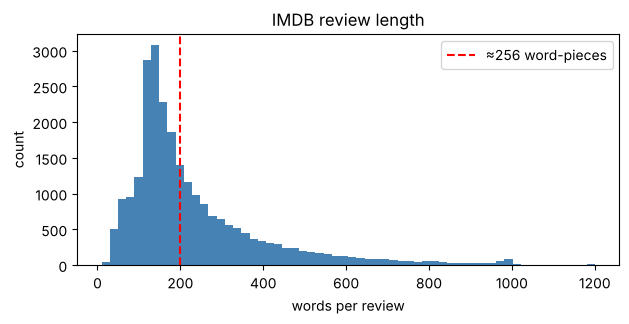

Share of reviews longer than ~200 words (will be truncated): 41.4%


In [5]:
# Class balance and review length
train_df = dataset["train"].to_pandas()
print(train_df["label"].value_counts().rename({0: "neg", 1: "pos"}))
lengths = train_df["text"].str.split().str.len()
print(lengths.describe().round(0))

plt.figure(figsize=(7, 3))
plt.hist(lengths.clip(upper=1200), bins=60, color="steelblue")
plt.axvline(200, color="red", ls="--", label="≈256 word-pieces")
plt.xlabel("words per review"); plt.ylabel("count"); plt.title("IMDB review length"); plt.legend()
plt.show()
print(f"Share of reviews longer than ~200 words (will be truncated): {(lengths > 200).mean():.1%}")

### Subset selection (CPU only)
On GPU we keep the full splits. On CPU we draw a balanced random subset of the training set and carve a small **validation** set out of it (used for per-epoch evaluation), and keep a separate balanced subset of the official **test** split for the final, untouched evaluation.

In [6]:
USE_FULL = device.type == "cuda"
N_TRAIN, N_VAL, N_TEST = 2000, 500, 2000     # used only on CPU

def balanced_subset(split, n, seed):
    split = split.shuffle(seed=seed)
    neg = split.filter(lambda x: x["label"] == 0).select(range(n // 2))
    pos = split.filter(lambda x: x["label"] == 1).select(range(n // 2))
    return datasets.concatenate_datasets([neg, pos]).shuffle(seed=seed)

if USE_FULL:
    split = dataset["train"].train_test_split(test_size=0.1, seed=SEED, stratify_by_column="label")
    raw_train, raw_val, raw_test = split["train"], split["test"], dataset["test"]
else:
    pool = balanced_subset(dataset["train"], N_TRAIN + N_VAL, SEED)
    split = pool.train_test_split(test_size=N_VAL, seed=SEED, stratify_by_column="label")
    raw_train, raw_val = split["train"], split["test"]
    raw_test = balanced_subset(dataset["test"], N_TEST, SEED)

for name, d in [("train", raw_train), ("val", raw_val), ("test", raw_test)]:
    print(f"{name:5s}: {len(d):6d} reviews | positive share = {np.mean(d['label']):.2f}")

train:   2000 reviews | positive share = 0.50
val  :    500 reviews | positive share = 0.50
test :   2000 reviews | positive share = 0.50


## 3. Tokenisation

In [7]:
MAX_LENGTH = 256
BATCH_SIZE = 16

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased", do_lower_case=True)

def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        padding="max_length",          # pad every review to MAX_LENGTH
        truncation=True,               # cut longer reviews
        max_length=MAX_LENGTH,
        return_attention_mask=True,    # 1 = real token, 0 = padding
        return_token_type_ids=True,    # single-sentence task -> all zeros
    )

def prepare(ds):
    ds = ds.map(tokenize_batch, batched=True, remove_columns=["text"])
    ds = ds.rename_column("label", "labels")
    ds.set_format("torch", columns=["input_ids", "token_type_ids", "attention_mask", "labels"])
    return ds

train_ds, val_ds, test_ds = prepare(raw_train), prepare(raw_val), prepare(raw_test)
print(train_ds)

sample = train_ds[0]
print("input_ids[:20]     :", sample["input_ids"][:20].tolist())
print("decoded            :", tokenizer.decode(sample["input_ids"][:20]))
print("attention_mask sum :", int(sample["attention_mask"].sum()), "/", MAX_LENGTH)

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})


input_ids[:20]     : [101, 2139, 19362, 10265, 2226, 1005, 1055, 2087, 12536, 2143, 2003, 2023, 1006, 3326, 1007, 2598, 21204, 2013, 20586, 1038]
decoded            : [CLS] depardieu's most notorious film is this ( 1974 ) groundbreaker from bertrand b
attention_mask sum : 256 / 256


## 4. Model & Trainer

In [8]:
model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2,
                                                      id2label={0: "Negative", 1: "Positive"},
                                                      label2id={"Negative": 0, "Positive": 1})
model.to(device)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f} M")

Trainable parameters: 109.5 M


In [9]:
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
            "f1": f1.compute(predictions=preds, references=labels)["f1"]}

In [10]:
EPOCHS = 2

training_args = TrainingArguments(
    output_dir="./bert-imdb",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="no",               # keep the disk clean; the final model is saved explicitly below
    logging_steps=10 if not USE_FULL else 100,
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,              # validation set for per-epoch monitoring; the test set stays untouched
    compute_metrics=compute_metrics,
)

In [11]:
t0 = time.time()
history = trainer.train()
print(f"Training time: {(time.time() - t0)/60:.1f} min")
history

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.345200,0.352376,0.844000,0.857143
2,0.171500,0.330222,0.868000,0.872093


Training time: 45.2 min


TrainOutput(global_step=250, training_loss=0.3564892630577087, metrics={'train_runtime': 2714.6245, 'train_samples_per_second': 1.474, 'train_steps_per_second': 0.092, 'total_flos': 526222110720000.0, 'train_loss': 0.3564892630577087, 'epoch': 2.0})

,epoch,eval_loss,eval_accuracy,eval_f1
12,1.0,0.3524,0.844,0.8571
26,2.0,0.3302,0.868,0.8721


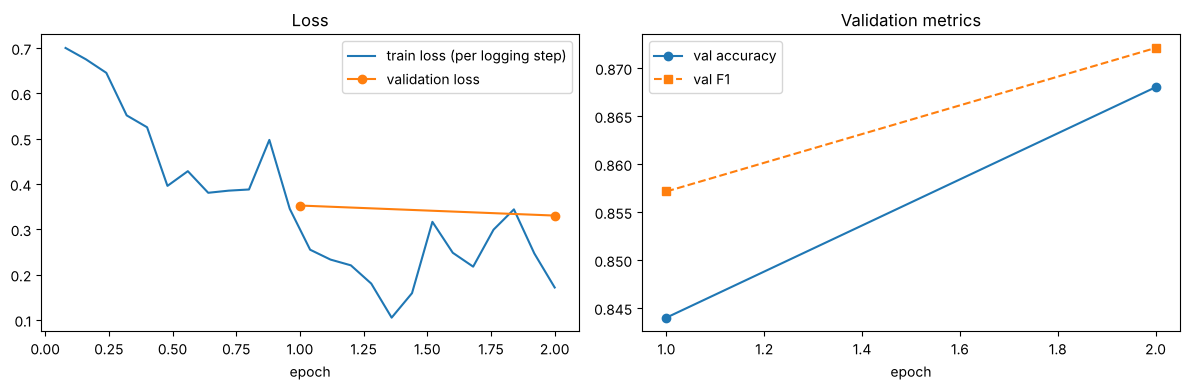

In [12]:
logs = pd.DataFrame(trainer.state.log_history)
train_logs = logs.dropna(subset=["loss"])[["step", "epoch", "loss"]]
eval_logs = logs.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1"]]
display(eval_logs.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(train_logs["epoch"], train_logs["loss"], label="train loss (per logging step)")
ax[0].plot(eval_logs["epoch"], eval_logs["eval_loss"], "o-", label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(eval_logs["epoch"], eval_logs["eval_accuracy"], "o-", label="val accuracy")
ax[1].plot(eval_logs["epoch"], eval_logs["eval_f1"], "s--", label="val F1")
ax[1].set_xlabel("epoch"); ax[1].set_title("Validation metrics"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Evaluation on the held-out test reviews

In [13]:
eval_metrics = trainer.evaluate(test_ds, metric_key_prefix="test")
eval_metrics

{'test_loss': 0.28681880235671997,
 'test_accuracy': 0.8845,
 'test_f1': 0.8892086330935252,
 'test_runtime': 209.951,
 'test_samples_per_second': 9.526,
 'test_steps_per_second': 0.3,
 'epoch': 2.0}

              precision    recall  f1-score   support

    Negative      0.920     0.842     0.879      1000
    Positive      0.854     0.927     0.889      1000

    accuracy                          0.884      2000
   macro avg      0.887     0.885     0.884      2000
weighted avg      0.887     0.884     0.884      2000



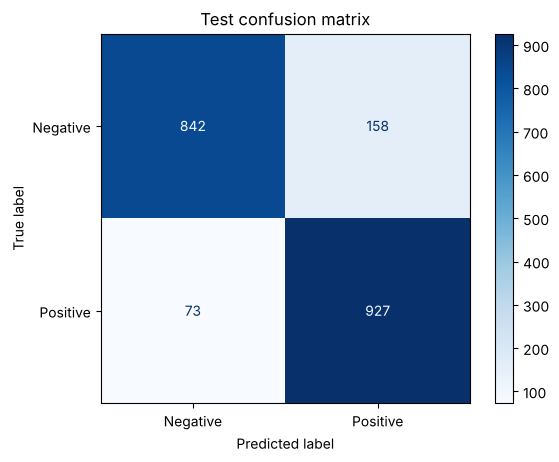

In [14]:
pred_out = trainer.predict(test_ds)
logits = pred_out.predictions
y_true = pred_out.label_ids
probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
y_pred = probs.argmax(axis=1)
conf = probs.max(axis=1)

print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("Test confusion matrix"); plt.show()

,confidence ≥,coverage,accuracy on kept,error rate on kept
0,0.50,1.000,0.884,0.116
1,0.60,0.968,0.896,0.104
2,0.70,0.932,0.910,0.090
3,0.80,0.890,0.925,0.075
4,0.90,0.809,0.946,0.054
5,0.95,0.660,0.972,0.028


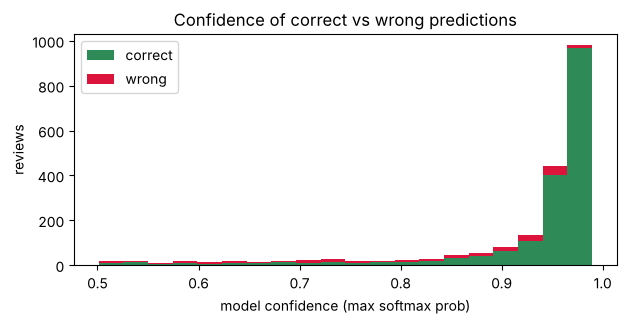

In [15]:
# How does accuracy depend on model confidence?  (useful to design an "escalate to a human" rule)
res = pd.DataFrame({"text": raw_test["text"], "label": y_true, "pred": y_pred, "conf": conf})
res["correct"] = res["label"] == res["pred"]

rows = []
for thr in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    kept = res[res["conf"] >= thr]
    rows.append({"confidence ≥": thr, "coverage": len(kept) / len(res),
                 "accuracy on kept": kept["correct"].mean(), "error rate on kept": 1 - kept["correct"].mean()})
thr_table = pd.DataFrame(rows)
display(thr_table.round(3))

plt.figure(figsize=(7, 3))
plt.hist([res.loc[res.correct, "conf"], res.loc[~res.correct, "conf"]], bins=20, stacked=True,
         label=["correct", "wrong"], color=["seagreen", "crimson"])
plt.xlabel("model confidence (max softmax prob)"); plt.ylabel("reviews"); plt.legend(); plt.title("Confidence of correct vs wrong predictions")
plt.show()

In [16]:
# A few of the most confident mistakes
pd.set_option("display.max_colwidth", 300)
worst = res[~res.correct].sort_values("conf", ascending=False).head(5).copy()
worst["label"] = worst["label"].map({0: "Negative", 1: "Positive"})
worst["pred"] = worst["pred"].map({0: "Negative", 1: "Positive"})
worst["text"] = worst["text"].str.slice(0, 300) + "..."
display(worst[["label", "pred", "conf", "text"]].round(3))

,label,pred,conf,text
1982,Positive,Negative,0.982,"This is not the kind of movie that really merits critical attention. It's not going to win any Oscars - it's really not a very good movie at all. Heck, it's not even really a movie - just a string of short disgusting, gross-out skits strung together in an effort to make entertainment. And as muc..."
1646,Positive,Negative,0.981,"You got to see it to believe it. Shot in Hollywood on the strip in the middle of the sleazy, anything goes 70s, this cheaply made flick must of really packed the inner city theatres back in the day. Then again, I bet it had a one week run. Actually, its pretty hilarious. The acting is dreadful, ..."
1316,Positive,Negative,0.976,"Tipping the Velvet has just three weeks ago been released in the UK and already I watch as countless letters flood to the national papers and TV guides, claiming that it possesses a thin plot, weak performances and an even weaker script.<br /><br />You find me incensed. This is heresy.<br /><br ..."
166,Positive,Negative,0.975,"I saw this movie with hopes of a good laugh but when I watched it I didn't stop laughing for weeks, they are such bad actors and it made this movie so much funnier to watch. ( BTW Ryan Dunn didn't eat the toy car, he shoved it up his ass) The random appearances from the skaters and Vitos parts w..."
1953,Negative,Positive,0.974,"Going into the movie with the right expectations, I somewhat liked this movie. Like most reviewers who have seen this movie, I fully agree that the plot was razor thin, clichéd, and I could predict every plot twist from the very beginning of the movie. But, the dancing sequences were VERY well d..."


### To-Do: what error rate is acceptable for a support team?

**Results recap (CPU run: 2 000 training reviews, 2 epochs, 256 tokens):**

| set | accuracy | F1 |
|---|---|---|
| validation, epoch 1 | 0.844 | 0.857 |
| validation, epoch 2 | 0.868 | 0.872 |
| **test (2 000 unseen reviews)** | **0.885** | **0.889** |

So the overall **error rate is ≈11.5 %**, i.e. about 1 message in 9 would be mislabelled. The errors are not symmetric: negative recall is only 0.842 (158 of 1 000 negative reviews predicted *Positive*) while positive recall is 0.927. For a support team this is the costly direction: an angry customer classified as happy is a **missed escalation**.

**What is acceptable?** It depends on how the signal is used:

- **Dashboards / trend monitoring** (weekly share of negative tickets, effect of a release): ~10 % random-ish error is acceptable, because errors average out over hundreds of tickets — what matters is the trend.
- **Routing / prioritising individual tickets**: a support lead would typically want **≤ 5 % error** on the tickets that are handled automatically, and especially a high recall on *Negative* (missing an unhappy customer costs more than double-checking a happy one).
- **Automated actions towards customers** (auto-replies, refunds, churn offers): needs ≤ 1–2 % error, or a human in the loop.

**The confidence table shows how to reach those targets without retraining:** keeping only predictions with confidence ≥ 0.90 covers **81 %** of messages with **5.4 %** error; at ≥ 0.95 the error falls to **2.8 %** for **66 %** of the volume. The remaining 19–34 % low-confidence messages are sent to a human. Note the limits: the most confident mistakes (table above, conf > 0.97) are sarcastic or mixed reviews ("not a very good movie at all… but hilarious"), so a confidence threshold reduces but does not eliminate errors — sampling audits are still needed.

## 6. `predict_sentiment` helper

In [17]:
def predict_sentiment(text):
    model.eval()
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=MAX_LENGTH)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad():
        logits = model(**inputs).logits
    probs = torch.softmax(logits, dim=-1)[0].cpu()
    label = model.config.id2label[int(probs.argmax())]
    return label, float(probs.max())

predict_sentiment("The onboarding emails were confusing, but the agent fixed everything politely.")

('Positive', 0.6885669231414795)

In [18]:
support_messages = [
    "The onboarding emails were confusing, but the agent fixed everything politely.",
    "I have been waiting two weeks for a refund and nobody answers my emails.",
    "Fantastic service, the issue was solved in five minutes. Thank you!",
    "The app crashes every time I open it. Useless.",
    "It's okay I guess, nothing special.",
    "Great, another update that breaks everything. Just great.",
]
for msg in support_messages:
    label, p = predict_sentiment(msg)
    flag = "  -> escalate to human" if p < 0.80 else ""
    print(f"{label:8s} ({p:.3f}){flag} | {msg}")

Positive (0.689)  -> escalate to human | The onboarding emails were confusing, but the agent fixed everything politely.
Negative (0.937) | I have been waiting two weeks for a refund and nobody answers my emails.
Positive (0.943) | Fantastic service, the issue was solved in five minutes. Thank you!
Negative (0.904) | The app crashes every time I open it. Useless.
Negative (0.503)  -> escalate to human | It's okay I guess, nothing special.
Positive (0.915) | Great, another update that breaks everything. Just great.


In [19]:
# Save the fine-tuned model + tokenizer so the assistant can be reloaded later
trainer.save_model("./bert-imdb/final")
tokenizer.save_pretrained("./bert-imdb/final")
print(os.listdir("./bert-imdb/final"))

['vocab.txt', 'training_args.bin', 'tokenizer_config.json', 'model.safetensors', 'special_tokens_map.json', 'config.json']


## 7. Reflection

**1. What lever most improved results?**

- **More training data / epochs.** Going from epoch 1 to epoch 2 lifted validation accuracy from **0.844 → 0.868** and lowered validation loss (0.352 → 0.330) with no sign of overfitting yet, so the model was still data/compute-limited. The single biggest lever is therefore *using the full 25 000 reviews* (only 8 % of the training set was used here because of CPU time). With the full set and 2 epochs on GPU, BERT-base typically reaches **≈ 92–94 %** on IMDB.
- **Sequence length** is the second lever: 41 % of reviews are longer than ~200 words and were truncated to 256 word-pieces, which cuts off conclusions such as "…but overall I loved it". `MAX_LENGTH=512` or head+tail truncation helps on long reviews (at ~2× the cost).
- **Hyper-parameters**: lr = 2e-5 with 10 % warm-up and weight decay 0.01 trained stably (train loss 0.36 average, smooth validation curve); this is the standard BERT recipe, so tuning it gives smaller gains than more data.
- **Data cleaning** matters for deployment more than for the IMDB score: reviews contain HTML (`<br /><br />`) which costs tokens; removing it frees context. For support tickets, removing signatures, quoted email threads and templates would be essential.

**2. Where would you add guardrails before deploying this sentiment signal live?**

- **Domain shift check**: the model learnt *movie reviews*, not support tickets. Before launch, label a few hundred real tickets and measure accuracy there; fine-tune again on them if needed.
- **Confidence threshold + human escalation**: use `predict_sentiment`'s probability — below ~0.8–0.9 the message goes to a human (see the threshold table: conf ≥ 0.9 → 5.4 % error on 81 % of traffic). The demo shows why: *"It's okay I guess, nothing special."* gets 0.503 (pure coin flip) and the mixed onboarding message 0.689.
- **Sarcasm / mixed sentiment**: *"Great, another update that breaks everything. Just great."* is predicted **Positive with 0.915 confidence** — a confidently wrong answer. Keyword rules (e.g. "refund", "cancel", "broken", "crash") should force escalation regardless of the model output.
- **Input limits**: language detection (the model is English-only), truncation of long threads, PII masking before logging.
- **Monitoring**: track the predicted negative rate and confidence distribution over time, audit a random sample weekly, and keep a feedback button for agents to correct labels (these become new training data).
- **Neutral class**: the model is forced to choose Positive/Negative; for tickets a third "neutral / mixed" outcome (or treating low confidence as neutral) is more honest.

**3. Which stakeholders benefit the most?**

- **Support lead** — benefits first and most directly: prioritising angry customers, measuring team-level satisfaction, and spotting spikes after incidents. They also own the escalation threshold.
- **Product manager** — benefits from aggregated sentiment per feature/release (trends tolerate the ~10 % error well), e.g. "negative tickets about onboarding doubled after v2.3".
- **Compliance officer** — benefits less from the score itself and more from the guardrails: they need the audit trail, PII handling, documented error rates and the guarantee that no automatic customer-facing decision is taken on a low-confidence prediction. They are a key *reviewer* of the deployment rather than its main beneficiary.